# Desafio 02: Modelo Temporal + Detector de Anomalia
## Sistema de Alerta Energético e Ambiental do AM
### Dataset: UHE Balbina (ANEEL) - 12.077 registros horários

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import mlflow
import mlflow.sklearn
from datetime import datetime, timedelta
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("imports ok")

imports ok


In [2]:
SAVE_DIR = os.path.abspath("../../ml/screenshoots/d02")
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Gráficos serão salvos em: {SAVE_DIR}")

Gráficos serão salvos em: C:\projetos-estudo\Sistema-Alerta-AM-ML-BotCity\ml\screenshoots\d02


## 1. Carregamento e preparação dos dados

Carregar dataset e reconstruir datetime:

In [3]:
df = pd.read_csv("../../ml/data/processed/balbina_processado.csv", sep=";")

inicio = datetime(2025, 1, 1, 1)
df["datetime"] = [inicio + timedelta(hours=i) for i in range(len(df))]
df = df.set_index("datetime")

print(df.shape)
print(df.head(3))
print(df.tail(3))

(12077, 7)
                     val_nivelmontante  val_niveljusante  val_vazaoafluente  \
datetime                                                                      
2025-01-01 01:00:00              46.04             24.60              287.0   
2025-01-01 02:00:00              46.04             24.59              287.0   
2025-01-01 03:00:00              46.04             24.59              287.0   

                     val_vazaodefluente  mes  dia  hora  
datetime                                                 
2025-01-01 01:00:00               284.0    1    1     1  
2025-01-01 02:00:00               284.0    1    1     2  
2025-01-01 03:00:00               284.0    1    1     3  
                     val_nivelmontante  val_niveljusante  val_vazaoafluente  \
datetime                                                                      
2026-05-19 03:00:00              49.78             27.02             2192.0   
2026-05-19 04:00:00              49.78             27.12          

## 2. Feature Engineering: criação de lags e features temporais

In [4]:
df["ano"] = df.index.year
df["mes_ano"] = df.index.to_period("M")

df["lag_1h"] = df["val_vazaodefluente"].shift(1)
df["lag_6h"] = df["val_vazaodefluente"].shift(6)
df["lag_24h"] = df["val_vazaodefluente"].shift(24)
df["lag_168h"] = df["val_vazaodefluente"].shift(168)

df["media_6h"] = df["val_vazaodefluente"].rolling(6).mean()
df["media_24h"] = df["val_vazaodefluente"].rolling(24).mean()

df = df.dropna()

print(f"Shape após lags: {df.shape}")
print(df[["val_vazaodefluente", "lag_1h", "lag_24h", "lag_168h", "media_24h"]].head(3))

Shape após lags: (11909, 15)
                     val_vazaodefluente  lag_1h  lag_24h  lag_168h   media_24h
datetime                                                                      
2025-01-08 01:00:00               278.0   278.0    278.0     284.0  278.833333
2025-01-08 02:00:00               278.0   278.0    278.0     284.0  278.833333
2025-01-08 03:00:00               283.0   278.0    278.0     284.0  279.041667


## 3. Divisão treino/teste e definição de features

In [5]:
FEATURES = [
    "val_nivelmontante", "val_niveljusante", "val_vazaoafluente",
    "mes", "dia", "hora", "ano",
    "lag_1h", "lag_6h", "lag_24h", "lag_168h",
    "media_6h", "media_24h"
]
TARGET = "val_vazaodefluente"

X = df[FEATURES]
y = df[TARGET]

# Split temporal: 80% treino, 20% teste
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
print(f"Período treino: {X_train.index[0]} a {X_train.index[-1]}")
print(f"Período teste:  {X_test.index[0]} a {X_test.index[-1]}")

Treino: (9527, 13) | Teste: (2382, 13)
Período treino: 2025-01-08 01:00:00 a 2026-02-08 23:00:00
Período teste:  2026-02-09 00:00:00 a 2026-05-19 05:00:00


## 4. Configuração do MLflow

In [6]:
import os

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

MLRUNS_PATH = os.path.abspath("../../ml/mlruns")
mlflow.set_tracking_uri(f"file:{MLRUNS_PATH}")
mlflow.set_experiment("alerta_am_temporal")

print(f"MLflow path: {MLRUNS_PATH}")
print("Experimento: alerta_am_temporal")

MLflow path: C:\projetos-estudo\Sistema-Alerta-AM-ML-BotCity\ml\mlruns
Experimento: alerta_am_temporal


## 4.1 Função de avaliação dos modelos

In [7]:
def avaliar_modelo(y_true, y_pred, nome):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"{nome}: MAE={mae:.2f} | RMSE={rmse:.2f} | R²={r2:.4f}")
    return mae, rmse, r2
print("Função avaliar_modelo definida!")

Função avaliar_modelo definida!


## 5. Modelo 1: GradientBoosting (baseline)

In [8]:
from sklearn.ensemble import GradientBoostingRegressor

with mlflow.start_run(run_name="gradient_boosting"):
    modelo_gb = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42
    )
    modelo_gb.fit(X_train, y_train)
    y_pred_gb = modelo_gb.predict(X_test)

    mae, rmse, r2 = avaliar_modelo(y_test, y_pred_gb, "GradientBoosting")

    cv_scores = cross_val_score(modelo_gb, X_train, y_train, cv=5, scoring="r2")
    print(f"CV R² médio: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

    mlflow.log_param("modelo", "GradientBoostingRegressor")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("max_depth", 4)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("r2", r2)
    mlflow.log_metric("cv_r2_mean", cv_scores.mean())
    mlflow.log_metric("cv_r2_std", cv_scores.std())
    mlflow.sklearn.log_model(modelo_gb, "model")

print("Run GradientBoosting concluído!")

GradientBoosting: MAE=79.78 | RMSE=140.66 | R²=0.8592


2026/06/09 12:01:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/06/09 12:01:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


CV R² médio: 0.9453 ± 0.0158
Run GradientBoosting concluído!


## 6. Modelo 2: XGBoost com lags

In [9]:
with mlflow.start_run(run_name="xgboost_lags"):
    modelo_xgb = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
    modelo_xgb.fit(X_train, y_train)
    y_pred_xgb = modelo_xgb.predict(X_test)

    mae, rmse, r2 = avaliar_modelo(y_test, y_pred_xgb, "XGBoost")

    cv_scores = cross_val_score(modelo_xgb, X_train, y_train, cv=5, scoring="r2")
    print(f"CV R² médio: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

    mlflow.log_param("modelo", "XGBRegressor")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("max_depth", 6)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("r2", r2)
    mlflow.log_metric("cv_r2_mean", cv_scores.mean())
    mlflow.log_metric("cv_r2_std", cv_scores.std())
    mlflow.sklearn.log_model(modelo_xgb, "model")

print("Run XGBoost concluído!")

XGBoost: MAE=76.50 | RMSE=137.96 | R²=0.8646


2026/06/09 12:01:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


CV R² médio: 0.9461 ± 0.0179


2026/06/09 12:01:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Run XGBoost concluído!


## 7. Modelo 3: SARIMAX

### 7.1 Estudo de estacionaridade (teste ADF)

In [10]:
from statsmodels.tsa.stattools import adfuller

# Usa dados diários para o SARIMAX
df_diario = df["val_vazaodefluente"].resample("D").mean()

resultado_adf = adfuller(df_diario)
print(f"Estatística ADF: {resultado_adf[0]:.4f}")
print(f"p-valor: {resultado_adf[1]:.4f}")
print(f"Valores críticos:")
for k, v in resultado_adf[4].items():
    print(f"  {k}: {v:.4f}")

if resultado_adf[1] < 0.05:
    print("\nSerie ESTACIONARIA: d=0")
else:
    print("\nSerie NAO ESTACIONARIA: d=1")

Estatística ADF: -2.4399
p-valor: 0.1308
Valores críticos:
  1%: -3.4439
  5%: -2.8675
  10%: -2.5700

Serie NAO ESTACIONARIA: d=1


### 7.2 Análise ACF e PACF para definir p e q

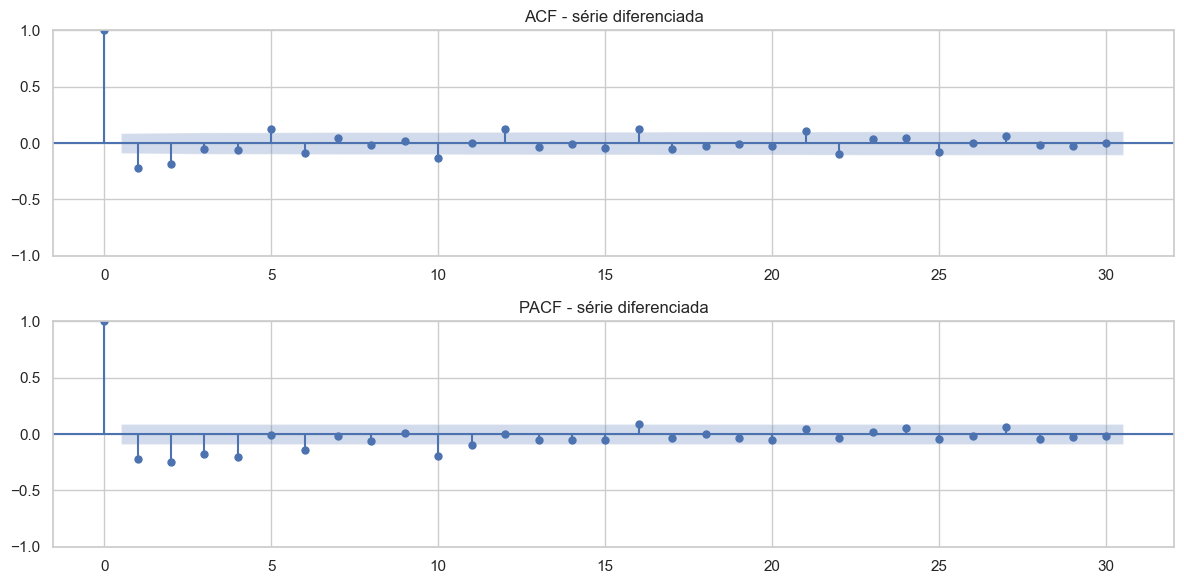

Gráfico ACF/PACF salvo!


In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

df_diff = df_diario.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(df_diff, lags=30, ax=axes[0], title="ACF - série diferenciada")
plot_pacf(df_diff, lags=30, ax=axes[1], title="PACF - série diferenciada")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "fig_acf_pacf.png"), dpi=150)
plt.show()
print("Gráfico ACF/PACF salvo!")

### 7.3 GridSearch: sazonalidade horária s=24

In [12]:
import itertools

# Amostra de 2000 pontos horários
serie_horaria = df["val_vazaodefluente"].tail(2000)
split_h = int(len(serie_horaria) * 0.8)
treino_h = serie_horaria.iloc[:split_h]
teste_h  = serie_horaria.iloc[split_h:]

print(f"Treino horário: {treino_h.shape} | Teste horário: {teste_h.shape}")

resultados_s24 = []
for p, q in [(1,1), (2,1), (1,2), (2,2)]:
    try:
        modelo = SARIMAX(
            treino_h,
            order=(p, 1, q),
            seasonal_order=(1, 1, 1, 24),
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        resultado = modelo.fit(disp=False)
        pred = resultado.forecast(steps=len(teste_h))
        r2   = r2_score(teste_h, pred)
        mae  = mean_absolute_error(teste_h, pred)
        rmse = np.sqrt(mean_squared_error(teste_h, pred))
        resultados_s24.append({"p": p, "q": q, "r2": r2, "mae": mae, "rmse": rmse})
        print(f"({p},1,{q})(1,1,1,24): MAE={mae:.2f} | RMSE={rmse:.2f} | R²={r2:.4f}")
    except Exception as e:
        print(f"({p},1,{q}) Erro: {str(e)[:50]}")

df_s24 = pd.DataFrame(resultados_s24).sort_values("r2", ascending=False)
print(f"\nMelhor combinação s=24:")
print(df_s24.head(3))

Treino horário: (1600,) | Teste horário: (400,)
(1,1,1)(1,1,1,24): MAE=188.49 | RMSE=234.76 | R²=0.5713
(2,1,1)(1,1,1,24): MAE=190.34 | RMSE=239.75 | R²=0.5529
(1,1,2)(1,1,1,24): MAE=190.29 | RMSE=239.77 | R²=0.5528
(2,1,2)(1,1,1,24): MAE=201.61 | RMSE=258.50 | R²=0.4802

Melhor combinação s=24:
   p  q        r2         mae        rmse
0  1  1  0.571348  188.488013  234.757073
1  2  1  0.552915  190.340818  239.751527
2  1  2  0.552833  190.288735  239.773556


### 7.4 SARIMAX com melhor parâmetro: registro no MLflow

In [13]:
with mlflow.start_run(run_name="sarimax"):
    modelo_sarimax = SARIMAX(
        treino_h,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 24),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    resultado_sarimax = modelo_sarimax.fit(disp=False)
    y_pred_sarimax = resultado_sarimax.forecast(steps=len(teste_h))

    mae, rmse, r2 = avaliar_modelo(teste_h, y_pred_sarimax, "SARIMAX")

    cv_r2 = r2  # SARIMAX nao suporta cross_val_score diretamente

    mlflow.log_param("modelo", "SARIMAX")
    mlflow.log_param("order", "(1,1,1)")
    mlflow.log_param("seasonal_order", "(1,1,1,24)")
    mlflow.log_param("sazonalidade", "horaria_s24")
    mlflow.log_param("amostra", "2000_horarios")
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("r2", r2)

print("Run SARIMAX concluído!")

SARIMAX: MAE=188.49 | RMSE=234.76 | R²=0.5713
Run SARIMAX concluído!


## 8. Comparativo dos 3 modelos

          Modelo    MAE   RMSE     R2
GradientBoosting  79.78 140.66 0.8592
         XGBoost  76.50 137.96 0.8646
         SARIMAX 188.49 234.76 0.5713


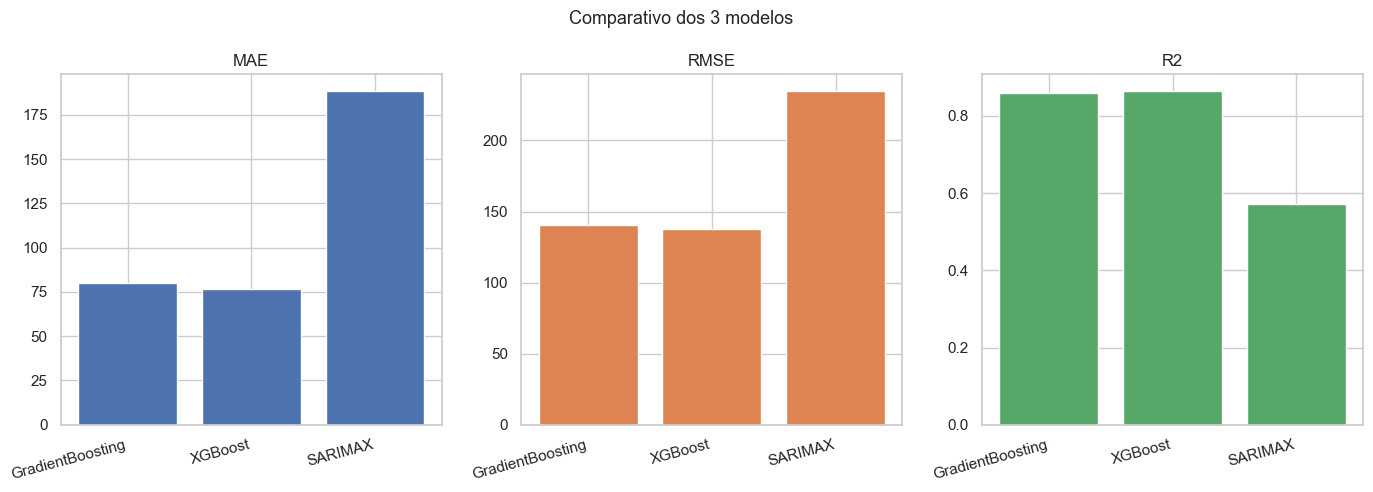

Gráfico salvo!


In [14]:
resultados = pd.DataFrame({
    "Modelo": ["GradientBoosting", "XGBoost", "SARIMAX"],
    "MAE":    [79.78, 76.50, 188.49],
    "RMSE":   [140.66, 137.96, 234.76],
    "R2":     [0.8592, 0.8646, 0.5713]
})

print(resultados.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
metrics = ["MAE", "RMSE", "R2"]
colors  = ["#4C72B0", "#DD8452", "#55A868"]

for ax, metric, color in zip(axes, metrics, colors):
    ax.bar(resultados["Modelo"], resultados[metric], color=color)
    ax.set_title(metric)
    ax.set_xticklabels(resultados["Modelo"], rotation=15, ha="right")

plt.suptitle("Comparativo dos 3 modelos", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "fig_comparativo_modelos_d02.png"), dpi=150)
plt.show()
print("Gráfico salvo!")

## 9. Modelo vencedor: XGBoost - predito vs real

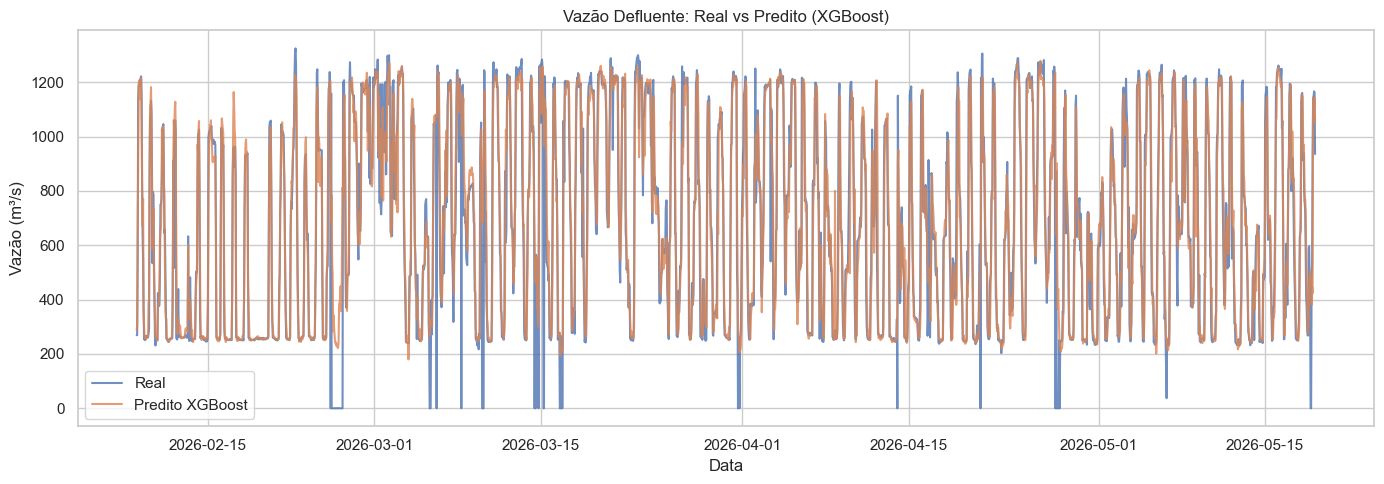

Gráfico salvo!


In [15]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test.values, label="Real", alpha=0.8)
ax.plot(y_test.index, y_pred_xgb, label="Predito XGBoost", alpha=0.8)
ax.set_title("Vazão Defluente: Real vs Predito (XGBoost)")
ax.set_xlabel("Data")
ax.set_ylabel("Vazão (m³/s)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "fig_predito_vs_real_d02.png"), dpi=150)
plt.show()
print("Gráfico salvo!")

## 10. Registro do modelo vencedor no MLflow Registry

In [16]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

runs = mlflow.search_runs(experiment_names=["alerta_am_temporal"])
run_xgb = runs[runs["tags.mlflow.runName"] == "xgboost_lags"].iloc[0]
run_id = run_xgb["run_id"]
artifact_uri = run_xgb["artifact_uri"]

print(f"Run ID XGBoost: {run_id}")
print(f"Artifact URI: {artifact_uri}")

model_name = "previsor_alerta_am"

try:
    client.create_registered_model(model_name)
except Exception:
    print(f"Modelo {model_name} já existe no registry")

version = client.create_model_version(
    name=model_name,
    source=artifact_uri + "/model",
    run_id=run_id
)

client.set_registered_model_alias(model_name, "production", version.version)

print(f"Modelo: {model_name}")
print(f"Versão: {version.version}")
print(f"Alias @production definido!")

Run ID XGBoost: 1b864763a89c4734981f853ebd6765e4
Artifact URI: file:C:\projetos-estudo\Sistema-Alerta-AM-ML-BotCity\ml\mlruns/389182684825236575/1b864763a89c4734981f853ebd6765e4/artifacts
Modelo previsor_alerta_am já existe no registry
Modelo: previsor_alerta_am
Versão: 4
Alias @production definido!


## 10.1 Detector de anomalia: IsolationForest

In [18]:
from sklearn.ensemble import IsolationForest

X_full = df[FEATURES]
y_full = df[TARGET]

iso = IsolationForest(contamination=0.02, random_state=42, n_estimators=200)
iso.fit(X_full)

scores = iso.predict(X_full)
scores_decision = iso.decision_function(X_full)

df_iso = df.copy()
df_iso["anomalia"] = scores
df_iso["score"] = scores_decision

print(f"Total: {len(df_iso)}")
print(f"Anomalias: {len(df_iso[df_iso['anomalia']==-1])} ({len(df_iso[df_iso['anomalia']==-1])/len(df_iso)*100:.1f}%)")

Total: 11909
Anomalias: 239 (2.0%)


## 11. Detector de anomalia híbrido: IsolationForest + Z-score sazonal

Distribuição de severidade híbrida:
severidade_hibrida
NORMAL      10655
MODERADO     1161
ALTO           88
CRITICO         5
Name: count, dtype: int64

Total anomalias: 1254
Percentual: 10.5%


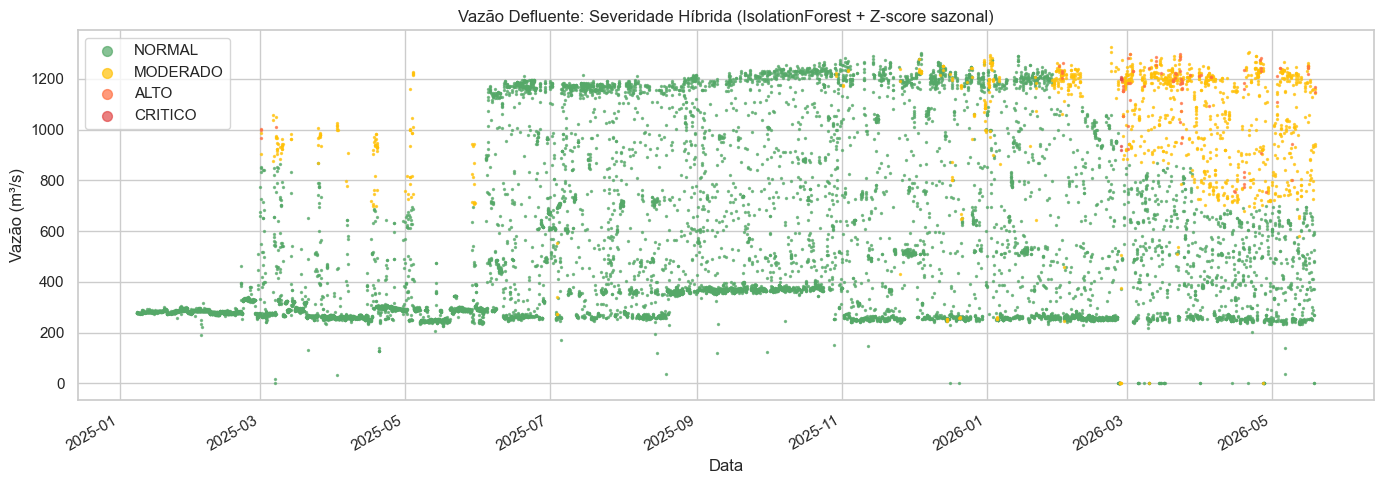

Gráfico salvo!


In [19]:
# Abordagem híbrida: IsolationForest + Z-score sazonal

# Z-score por mês
df_train_aux = X_train.copy()
df_train_aux["vazao"] = y_train
stats_mes = df_train_aux.groupby("mes")["vazao"].agg(["mean", "std"]).reset_index()
stats_mes.columns = ["mes", "media_mes", "std_mes"]

df_full_aux = df_iso.copy()
df_full_aux["vazao"] = df_iso["val_vazaodefluente"]
df_full_aux = df_full_aux.merge(stats_mes, on="mes", how="left")
df_full_aux.index = df_iso.index

df_full_aux["z_score"] = np.abs((df_full_aux["vazao"] - df_full_aux["media_mes"]) / df_full_aux["std_mes"])

def classificar_hibrido(row):
    iso_anomalia = row["anomalia"] == -1
    z_alto       = row["z_score"] > 2.5

    if iso_anomalia and z_alto:
        if row["score"] < -0.04:
            return "CRITICO"
        else:
            return "ALTO"
    elif iso_anomalia or z_alto:
        return "MODERADO"
    else:
        return "NORMAL"

df_full_aux["severidade_hibrida"] = df_full_aux.apply(classificar_hibrido, axis=1)

print("Distribuição de severidade híbrida:")
print(df_full_aux["severidade_hibrida"].value_counts())
print(f"\nTotal anomalias: {len(df_full_aux[df_full_aux['severidade_hibrida'] != 'NORMAL'])}")
print(f"Percentual: {len(df_full_aux[df_full_aux['severidade_hibrida'] != 'NORMAL'])/len(df_full_aux)*100:.1f}%")

fig, ax = plt.subplots(figsize=(14, 5))
cores = {"NORMAL": "#55A868", "MODERADO": "#FFC107", "ALTO": "#FF7043", "CRITICO": "#E24B4A"}
for sev, cor in cores.items():
    mask = df_full_aux["severidade_hibrida"] == sev
    ax.scatter(df_full_aux.index[mask], df_full_aux["vazao"][mask],
               c=cor, label=sev, s=2, alpha=0.7)
ax.set_title("Vazão Defluente: Severidade Híbrida (IsolationForest + Z-score sazonal)")
ax.set_xlabel("Data")
ax.set_ylabel("Vazão (m³/s)")
ax.legend(markerscale=5)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "fig_anomalias_hibrido.png"), dpi=150)
plt.show()
print("Gráfico salvo!")